In [1]:
!pip install -q datasets

In [2]:
import time
import torch, torch.nn as nn, torch.optim as optim
from torchvision import transforms, models
from torch.utils.data import DataLoader, Dataset
from datasets import load_dataset
import matplotlib.pyplot as plt
import pandas as pd

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

EPOCHS = 5        # increase for better accuracy
BATCH_SIZE = 32
LR = 1e-3

Using device: cuda


In [3]:
# Load Cats vs Dogs from Hugging Face (3,000-image sample keeps training fast)
raw = load_dataset("microsoft/cats_vs_dogs", split="train").shuffle(seed=42).select(range(3000))
split = raw.train_test_split(test_size=1000, seed=42)

norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), norm])
val_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(), norm])

class HFImages(Dataset):
    def __init__(self, ds, tf):
        self.ds, self.tf = ds, tf
    def __len__(self):
        return len(self.ds)
    def __getitem__(self, i):
        row = self.ds[i]
        return self.tf(row["image"].convert("RGB")), row["labels"]

train_ds = HFImages(split["train"], train_tf)
val_ds = HFImages(split["test"], val_tf)
train_dl = DataLoader(train_ds, BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_dl = DataLoader(val_ds, BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(len(train_ds), "train /", len(val_ds), "val images")

README.md:   0%|          | 0.00/8.16k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  330MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  391MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/23410 [00:00<?, ? examples/s]

2000 train / 1000 val images


In [4]:
def build_model(name):
    if name == "AlexNet":
        m = models.alexnet(weights=models.AlexNet_Weights.DEFAULT)
        for p in m.parameters(): p.requires_grad = False
        m.classifier[6] = nn.Linear(4096, 2)
    elif name == "VGG16":
        m = models.vgg16(weights=models.VGG16_Weights.DEFAULT)
        for p in m.parameters(): p.requires_grad = False
        m.classifier[6] = nn.Linear(4096, 2)
    elif name == "ResNet50":
        m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        for p in m.parameters(): p.requires_grad = False
        m.fc = nn.Linear(2048, 2)
    elif name == "EfficientNetB0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
        for p in m.parameters(): p.requires_grad = False
        m.classifier[1] = nn.Linear(1280, 2)
    return m.to(device)  # new head is trainable by default

In [5]:
def run_epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    model.train(train)
    # keep frozen BatchNorm layers in eval mode for stable transfer learning
    if train:
        for mod in model.modules():
            if isinstance(mod, nn.BatchNorm2d): mod.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=device.type == "cuda"):
                out = model(x)
                loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n


def train_model(name):
    model = build_model(name)
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=LR)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_acc, start = 0, time.time()
    for ep in range(EPOCHS):
        tl, ta = run_epoch(model, train_dl, criterion, optimizer)
        vl, va = run_epoch(model, val_dl, criterion)
        for k, v in zip(hist, [tl, vl, ta, va]): hist[k].append(v)
        best_acc = max(best_acc, va)
        print(f"{name} | epoch {ep+1}/{EPOCHS} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}")
    hist["time"] = time.time() - start
    hist["trainable"] = trainable
    hist["best_val_acc"] = best_acc
    return hist

In [6]:
results = {}
for name in ["AlexNet", "VGG16", "ResNet50", "EfficientNetB0"]:
    print(f"\n===== {name} =====")
    results[name] = train_model(name)
    torch.cuda.empty_cache()


===== AlexNet =====
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 185MB/s]


AlexNet | epoch 1/5 | train loss 0.1935 acc 0.9210 | val loss 0.1284 acc 0.9450
AlexNet | epoch 2/5 | train loss 0.0924 acc 0.9630 | val loss 0.1271 acc 0.9500
AlexNet | epoch 3/5 | train loss 0.0810 acc 0.9705 | val loss 0.1265 acc 0.9500
AlexNet | epoch 4/5 | train loss 0.0565 acc 0.9805 | val loss 0.1371 acc 0.9460
AlexNet | epoch 5/5 | train loss 0.0418 acc 0.9845 | val loss 0.1193 acc 0.9560

===== VGG16 =====
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:07<00:00, 72.5MB/s]


VGG16 | epoch 1/5 | train loss 0.0791 acc 0.9725 | val loss 0.0330 acc 0.9880
VGG16 | epoch 2/5 | train loss 0.0338 acc 0.9875 | val loss 0.0386 acc 0.9870
VGG16 | epoch 3/5 | train loss 0.0272 acc 0.9905 | val loss 0.0357 acc 0.9870
VGG16 | epoch 4/5 | train loss 0.0176 acc 0.9920 | val loss 0.0285 acc 0.9870
VGG16 | epoch 5/5 | train loss 0.0171 acc 0.9940 | val loss 0.0308 acc 0.9900

===== ResNet50 =====
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 176MB/s]


ResNet50 | epoch 1/5 | train loss 0.1841 acc 0.9725 | val loss 0.0653 acc 0.9920
ResNet50 | epoch 2/5 | train loss 0.0442 acc 0.9945 | val loss 0.0416 acc 0.9920
ResNet50 | epoch 3/5 | train loss 0.0278 acc 0.9945 | val loss 0.0315 acc 0.9920
ResNet50 | epoch 4/5 | train loss 0.0194 acc 0.9990 | val loss 0.0252 acc 0.9940
ResNet50 | epoch 5/5 | train loss 0.0144 acc 0.9990 | val loss 0.0221 acc 0.9940

===== EfficientNetB0 =====
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 150MB/s]


EfficientNetB0 | epoch 1/5 | train loss 0.1822 acc 0.9480 | val loss 0.0567 acc 0.9930
EfficientNetB0 | epoch 2/5 | train loss 0.0518 acc 0.9900 | val loss 0.0361 acc 0.9940
EfficientNetB0 | epoch 3/5 | train loss 0.0361 acc 0.9925 | val loss 0.0289 acc 0.9950
EfficientNetB0 | epoch 4/5 | train loss 0.0278 acc 0.9945 | val loss 0.0250 acc 0.9950
EfficientNetB0 | epoch 5/5 | train loss 0.0228 acc 0.9950 | val loss 0.0222 acc 0.9940


In [7]:
summary = pd.DataFrame({
    name: {
        "Final Train Acc": h["train_acc"][-1],
        "Final Val Acc": h["val_acc"][-1],
        "Best Val Acc": h["best_val_acc"],
        "Final Train Loss": h["train_loss"][-1],
        "Final Val Loss": h["val_loss"][-1],
        "Training Time (s)": h["time"],
        "Trainable Params": h["trainable"],
    } for name, h in results.items()
}).T.round(4)
summary

,Final Train Acc,Final Val Acc,Best Val Acc,Final Train Loss,Final Val Loss,Training Time (s),Trainable Params
AlexNet,0.9845,0.956,0.956,0.0418,0.1193,54.6525,8194.0
VGG16,0.9940,0.990,0.990,0.0171,0.0308,61.6959,8194.0
ResNet50,0.9990,0.994,0.994,0.0144,0.0221,57.1619,4098.0
EfficientNetB0,0.9950,0.994,0.995,0.0228,0.0222,57.1139,2562.0


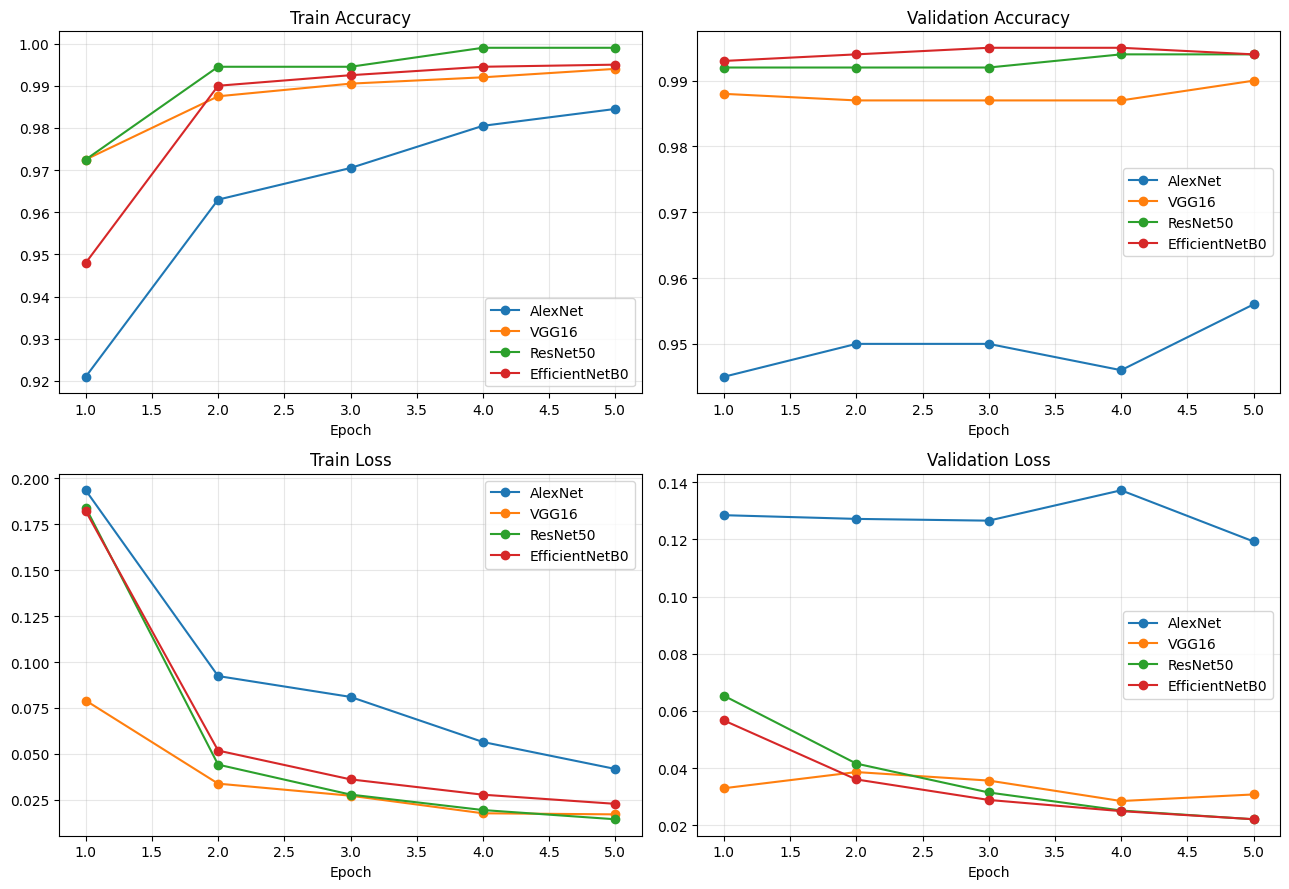

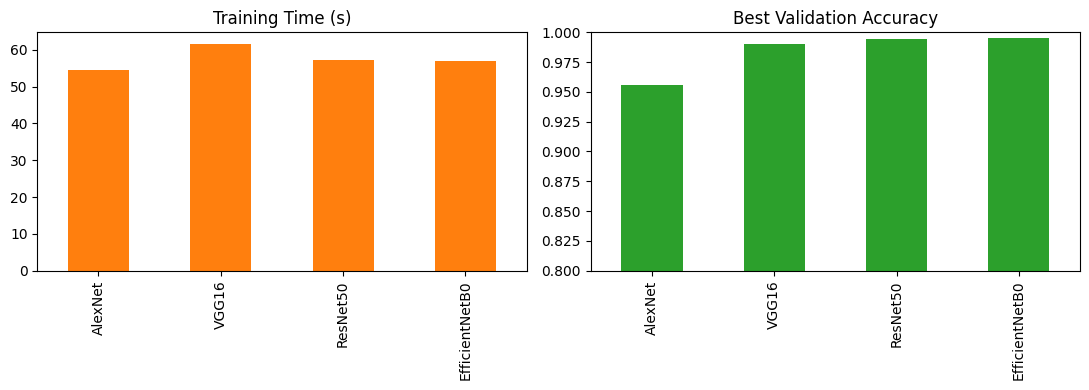

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
for name, h in results.items():
    ep = range(1, EPOCHS + 1)
    ax[0, 0].plot(ep, h["train_acc"], marker="o", label=name)
    ax[0, 1].plot(ep, h["val_acc"], marker="o", label=name)
    ax[1, 0].plot(ep, h["train_loss"], marker="o", label=name)
    ax[1, 1].plot(ep, h["val_loss"], marker="o", label=name)
for a, t in zip(ax.flat, ["Train Accuracy", "Validation Accuracy", "Train Loss", "Validation Loss"]):
    a.set_title(t); a.set_xlabel("Epoch"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
summary["Training Time (s)"].plot.bar(ax=ax[0], color="tab:orange", title="Training Time (s)")
summary["Best Val Acc"].plot.bar(ax=ax[1], color="tab:green", title="Best Validation Accuracy", ylim=(0.8, 1))
plt.tight_layout(); plt.show()